# 06 — Physics baselines: ETAS, rate-and-state, and the hybrid

**Question (Part 2 of the project):** Part 1 found that GPS uplift adds no measurable weekly forecasting skill beyond past seismicity, but it only compared the ML models with simple benchmarks. Two physics models are much stronger benchmarks:

- **ETAS** (Epidemic-Type Aftershock Sequence): every earthquake raises the chance of further earthquakes for a while (Omori's law), more so for larger ones. It uses past earthquakes only.
- **The hybrid of Hainzl, Dahm & Tramelli (2026)**: ETAS whose background rate comes from a **rate-and-state (RS)** model driven by the uplift since 1905.

This notebook:

1. implements the three models and checks them against the authors' published results (milestone 3);
2. *(milestone 4)* turns them into weekly forecasts and compares them with the Part 1 models on the same test weeks and scores.

## 1. The models, implemented and checked

The rate of earthquakes with M ≥ 0.45 (Md ≥ 0.5 at 0.1 resolution) at time t, in events per day:

$$\lambda(t) = \mu(t) + \sum_{t - 100\,\text{d} \le t_i < t} K\, 10^{\alpha (m_i - 0.45)}\, (c + t - t_i)^{-p}$$

- **ETAS:** μ is a constant. K (productivity), α (how much more productive larger events are), c and p (Omori's law) describe triggering. As in Hainzl et al., an event only triggers for 100 days.
- **RS:** no triggering. The rate responds to the stress S(t), here the uplift in metres plus a slow background loading Aσ′/t_a per day:
  $$\mu(t) = \frac{r\, e^{S(t)/A\sigma'}}{1 + \frac{1}{t_a}\int_{1905}^{t} e^{S/A\sigma'}\,dt'}$$
  The numerator makes the rate rise steeply when the uplift reaches new heights. The denominator remembers how much of the fault population earlier uplift has already used up: this is why the whole history since 1905 matters, including the 1950s, 1970s and 1980s episodes.
- **RS + ETAS (the hybrid):** ETAS with the RS rate as its background μ(t).

**Fitting** is by maximum likelihood: log L = Σ log λ(tᵢ) − ∫ λ dt over the window (high rates where earthquakes happened, few expected overall). As in the paper, the window runs from 2005.0 to the end of their uplift file (5 Feb 2025), and events before 2005 still count as triggers. (Their code converts 2005.0 to days with a straight-line fit of decimal year against date, which lands half a day early, on 31 Dec 2004; we keep it to fit exactly the same data.) Time is in days.

**Code:** `src/physics.py`, adapted from the authors' Python code (Hainzl 2026, Zenodo, doi:10.5281/zenodo.18413119, CC BY 4.0). The likelihood is theirs; the RS rate is computed in log space (no overflow), the triggering sums are vectorised, and fits use bounds and several starting points.

**Data:** their files in `data/raw/hainzl/` (fetched by `scripts/download_data.py`): the uplift since 1905 (`gps.dat`: levelling, then GPS station RITE) and their catalogue (`campi-flegrei.kat`, from GOSSIP).

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import b_value_mle
from src.gps import MJD_EPOCH
from src.physics import (FIT_START_YEAR, MCUT, MODELS, branching_ratio, expected_counts, fit, intensities,
                         load_catalogue, load_uplift, negative_log_likelihood, prepare, simulate_etas,
                         weekly_forecast, year_to_mjd)

HAINZL = Path("../data/raw/hainzl")
DAYS_PER_YEAR = 365.25
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def to_time(mjd):
    return MJD_EPOCH + pd.to_timedelta(np.asarray(mjd), unit="D")


uplift, events = load_uplift(HAINZL), load_catalogue(HAINZL)
t1, t2 = year_to_mjd(FIT_START_YEAR, uplift), uplift["mjd"].iloc[-1]
data = prepare(events, uplift, t1, t2)
print(f"Uplift: {len(uplift)} weeks, {uplift['year'].iloc[0]:.1f} to {uplift['year'].iloc[-1]:.2f}")
print(f"Fit window: {to_time(t1):%Y-%m-%d} to {to_time(t2):%Y-%m-%d}")
print(f"Events with M ≥ {MCUT}: {len(data['t'])} up to the window's end, {len(data['target'])} in the window")

Uplift: 6258 weeks, 1905.2 to 2025.10
Fit window: 2004-12-31 to 2025-02-05
Events with M ≥ 0.45: 4305 up to the window's end, 4250 in the window


### 1.1 Their catalogue against ours

Their catalogue should be the GOSSIP catalogue we cleaned in phase 3. Events with M ≥ 0.45 since 2005, by year, up to the end of their file (25 Feb 2025):

In [2]:
ours = pd.read_parquet("../data/processed/catalogue.parquet")
start, end = pd.Timestamp("2005-01-01", tz="UTC"), to_time(events["mjd"].max())
ours = ours[(ours["time"] >= start) & (ours["time"] <= end) & (ours["md"] >= MCUT)]
theirs = pd.Series(to_time(events["mjd"]))
theirs = theirs[theirs >= start]
pd.DataFrame({"theirs": theirs.dt.year.value_counts(), "ours": ours["time"].dt.year.value_counts()}).sort_index().T

,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
theirs,17,16,1,4,2,14,8,26,1,19,28,38,33,95,118,177,222,379,1177,1774,735
ours,17,16,1,4,2,14,8,26,1,19,28,38,33,95,118,177,222,379,1177,1775,808


### 1.2 Same likelihood as the authors' code?

The authors' files give their fitted parameters and the resulting −log L. If our code computes the same −log L at their parameters, the two implementations agree. (During development, our RS rate also matched their function to 1e-13 at several parameter sets.)

In [3]:
def read_published(name, keys):
    """One row of fitted parameters from the authors' parameter-*.dat files (time in days)."""
    return dict(zip(keys, np.loadtxt(HAINZL / name)))


published = {
    "rs": read_published("parameter-RS.dat", ["r", "asig", "ta", "nll", "aic"]),
    "rs_etas": read_published("parameter-RSETAS.dat", ["r", "asig", "ta", "K", "alpha", "c", "p", "nll", "aic"]),
}
for model, values in published.items():
    params = {k: values[k] for k in MODELS[model]}
    print(f"{model:8s} -log L at their parameters: ours {negative_log_likelihood(params, data, model):10.3f}, "
          f"their file {values['nll']:10.3f}")

rs       -log L at their parameters: ours   1229.636, their file   1229.636
rs_etas  -log L at their parameters: ours  -4125.891, their file  -4125.892


### 1.3 Fitting the three models

Each model is fitted from the authors' starting point plus 4 random ones (seeded). α, c and p trade off against each other, so the likelihood has long, flat valleys, and one start can get stuck. A constant-rate Poisson model is added for reference. AIC = 2·(−log L) + 2·(number of parameters): lower is better, and a difference of more than about 10 is decisive.

In [4]:
fits = {}
for model in MODELS:
    start = time.perf_counter()
    fits[model] = fit(data, model)
    print(f"{model}: fitted in {time.perf_counter() - start:.0f} s")

n = len(data["target"])
poisson_nll = n - n * np.log(n / (t2 - t1))
comparison = pd.DataFrame({m: {"parameters": len(MODELS[m]), "-log L": f["nll"], "AIC": f["aic"]}
                           for m, f in fits.items()}).T
comparison.loc["poisson"] = [1, poisson_nll, 2 * poisson_nll + 2]
comparison["AIC - hybrid's"] = comparison["AIC"] - comparison.loc["rs_etas", "AIC"]
comparison.round(1)

etas: fitted in 15 s


rs: fitted in 0 s


rs_etas: fitted in 61 s


,parameters,-log L,AIC,AIC - hybrid's
etas,5.0,-4046.3,-8082.5,155.3
rs,3.0,1229.6,2465.3,10703.1
rs_etas,7.0,-4125.9,-8237.8,0.0
poisson,1.0,6572.5,13147.1,21384.9


Our hybrid fit against Table 1 of Hainzl et al. (2026) and their parameter file, in the paper's units (rates per year, t_a in years):

In [5]:
def in_paper_units(p):
    return {"r (events/yr)": p["r"] * DAYS_PER_YEAR, "Aσ′ (m)": p["asig"], "t_a (yr)": p["ta"] / DAYS_PER_YEAR,
            "K": p["K"], "α": p["alpha"], "c (days)": p["c"], "p": p["p"]}


pd.DataFrame({
    "Table 1": {"r (events/yr)": 7.5, "Aσ′ (m)": 0.20, "t_a (yr)": 34.2, "K": 0.04, "α": 0.24, "p": 1.08},
    "their file": in_paper_units(published["rs_etas"]),
    "our fit": in_paper_units(fits["rs_etas"]["params"]),
}).round(4)

,Table 1,their file,our fit
r (events/yr),7.50,7.4679,7.4790
Aσ′ (m),0.20,0.1973,0.1971
t_a (yr),34.20,34.2074,34.3790
K,0.04,0.0428,0.0427
α,0.24,0.2416,0.2418
p,1.08,1.0811,1.0827
c (days),NaN,0.0006,0.0006


Did the starts agree? Each row is one start's result for the hybrid:

In [6]:
fits["rs_etas"]["runs"].style.format("{:.4g}", subset=MODELS["rs_etas"] + ["nll"])

,nll,r,asig,ta,K,alpha,c,p,converged
0,-4126,0.02048,0.1971,1.256e+04,0.04266,0.2418,0.0006105,1.083,True
1,-4126,0.02048,0.1971,1.256e+04,0.04267,0.2418,0.0006107,1.083,True
2,-4126,0.02047,0.1971,1.256e+04,0.04266,0.2418,0.0006105,1.083,True
3,-4122,0.0004266,0.2229,1.046e+06,0.04252,0.2401,0.0006121,1.084,True
4,-4126,0.02048,0.1971,1.256e+04,0.04267,0.2418,0.0006106,1.083,True


### 1.4 Can the fit recover known parameters?

Matching the authors shows the code does what theirs does, not that the method finds the truth. So: simulate 30 catalogues of 15 years from ETAS with known parameters (Table 1's triggering, a constant background of 0.05 events/day, Gutenberg–Richter magnitudes with b = 1), fit each, and compare.

`simulate_etas` works generation by generation: background events first; then each event gets a Poisson number of direct aftershocks (mean = productivity × the Omori kernel integrated over its remaining time, up to 100 days), with delays from the truncated Omori law and new magnitudes; repeat until a generation has no aftershocks. Milestone 4 will use it to check the weekly expected counts.

Two checks: the mean of the fits should be within about 2 standard errors of the truth; and twice the gap in −log L between the fit and the truth (the likelihood-ratio statistic) should average about 5, the number of parameters, if the likelihood is right.

In [7]:
TRUE = {"mu": 0.05, "K": 0.043, "alpha": 0.24, "c": 0.0006, "p": 1.08}
LENGTH = 15 * DAYS_PER_YEAR
no_uplift = pd.DataFrame({"mjd": [0.0, LENGTH], "year": [0.0, 15.0], "uplift": [0.0, 0.0]})  # unused by ETAS

rng = np.random.default_rng(42)
recovered = []
for i in range(30):
    sim = simulate_etas(TRUE, 0.0, LENGTH, b=1.0, rng=rng)
    sim_data = prepare(sim, no_uplift, 0.0, LENGTH)
    f = fit(sim_data, "etas", n_random=2, seed=i)
    recovered.append({"events": len(sim), "lr": 2 * (negative_log_likelihood(TRUE, sim_data, "etas") - f["nll"]),
                      **f["params"]})
recovered = pd.DataFrame(recovered)

print(f"Events per catalogue: median {recovered['events'].median():.0f} "
      f"(range {recovered['events'].min()}–{recovered['events'].max()})")
print(f"Likelihood-ratio statistic: mean {recovered['lr'].mean():.2f} (theory: 5)")
print(f"Correlation of log c and p across fits: {np.corrcoef(np.log(recovered['c']), recovered['p'])[0, 1]:.2f}")
check = pd.DataFrame({"true": TRUE, "mean of fits": recovered[list(TRUE)].mean(),
                      "sd of fits": recovered[list(TRUE)].std()})
check["bias in standard errors"] = (check["mean of fits"] - check["true"]) / (check["sd of fits"] / np.sqrt(len(recovered)))
check.round(4)

Events per catalogue: median 1344 (range 982–1675)
Likelihood-ratio statistic: mean 4.17 (theory: 5)
Correlation of log c and p across fits: 0.79


,true,mean of fits,sd of fits,bias in standard errors
mu,0.0500,0.0507,0.0056,0.6757
K,0.0430,0.0432,0.0024,0.5018
alpha,0.2400,0.2393,0.0339,-0.1118
c,0.0006,0.0006,0.0001,0.5713
p,1.0800,1.0799,0.0165,-0.0212


### 1.5 How the models explain the seismicity

A model's rate has two parts: the **background** μ(t) and the **triggered** part (aftershocks of earlier events). Below, each model's expected number of events per calendar year is split into the two. These are in-sample: the triggered part uses the earthquakes that actually happened, so ETAS and the hybrid follow the observed counts closely by construction. What differs is how they explain them.

Two summaries:

- **Share of events attributed to the background:** the mean of μ(tᵢ)/λ(tᵢ) over the events, i.e. each event's chance of being a background event rather than an aftershock.
- **Branching ratio:** the average number of direct aftershocks per event. It depends on the magnitude distribution, so it uses the window's b-value (`b_value_mle` from phase 3, with Md ≥ 0.5 binned, equivalent to M ≥ 0.45). Near 1, sequences barely die out.

In [8]:
def background_share(model):
    background, total, _ = intensities(fits[model]["params"], data, model)
    return pd.Series(background / total, index=to_time(data["t"][data["target"]]).year)


b, b_sigma, _ = b_value_mle(pd.Series(data["m"][data["target"]]), mc=0.5)
print(f"b-value in the window: {b:.2f} ± {b_sigma:.2f}")
for m in ["etas", "rs_etas"]:
    print(f"{m}: branching ratio {branching_ratio(fits[m]['params'], b):.2f}, "
          f"share of events attributed to the background {background_share(m).mean():.0%}")
shares = pd.DataFrame({m: background_share(m).groupby(level=0).mean() for m in ["etas", "rs_etas"]})
shares.loc[[2005, 2010, 2015, 2018, 2020, 2022, 2023, 2024]].round(2).T

b-value in the window: 0.88 ± 0.01
etas: branching ratio 0.97, share of events attributed to the background 3%
rs_etas: branching ratio 0.82, share of events attributed to the background 17%


,2005,2010,2015,2018,2020,2022,2023,2024
etas,0.22,0.2,0.20,0.08,0.05,0.02,0.01,0.0
rs_etas,0.20,0.2,0.24,0.25,0.30,0.29,0.14,0.1


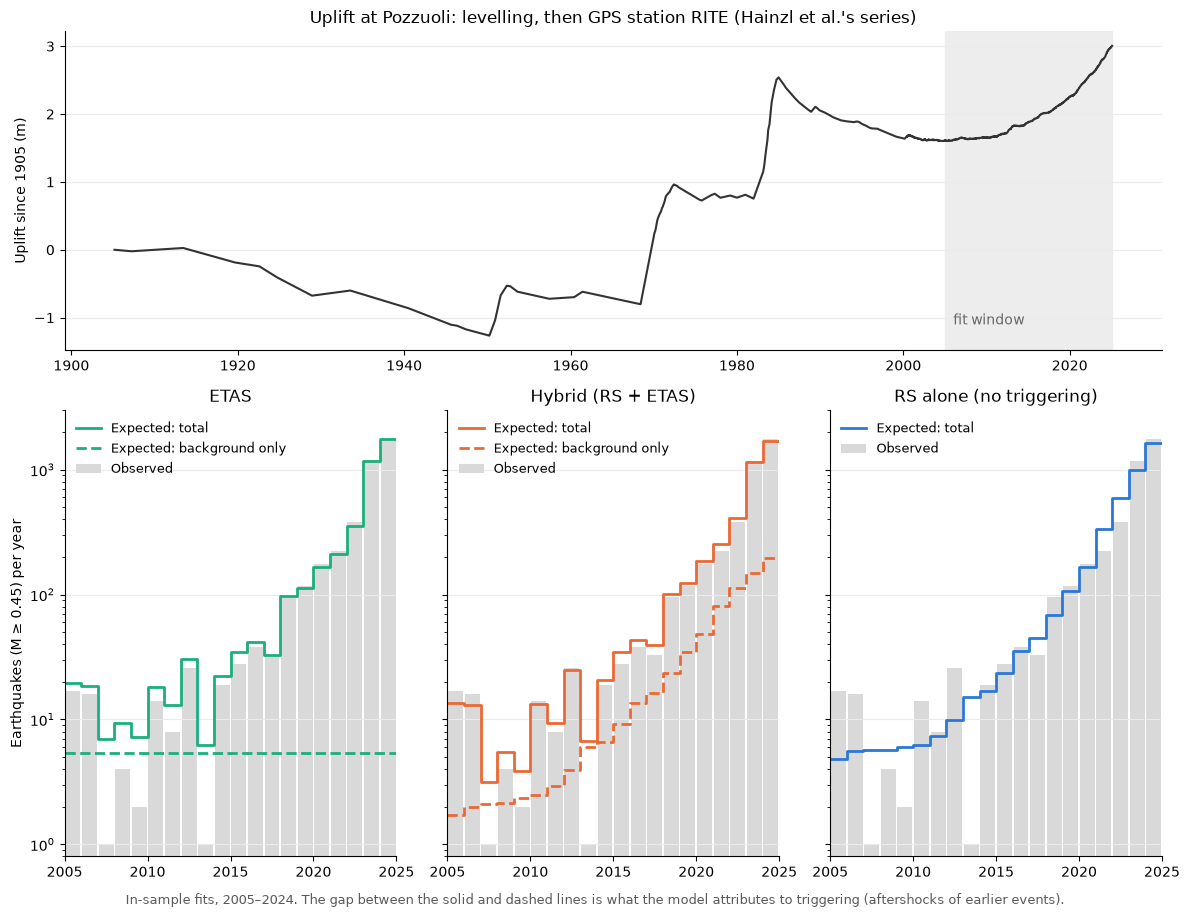

In [9]:
# Expected events per full calendar year in the window, split into background and triggered.
years = np.arange(2005, 2025)
edges = np.array([(pd.Timestamp(f"{y}-01-01", tz="UTC") - MJD_EPOCH) / pd.Timedelta(days=1)
                  for y in range(2005, 2026)])
observed = np.histogram(data["t"][data["target"]], edges)[0]

fig = plt.figure(figsize=(12, 9))
layout = fig.add_gridspec(2, 3, height_ratios=[1, 1.4])
top = fig.add_subplot(layout[0, :])
top.plot(uplift["year"], uplift["uplift"], color="0.2", linewidth=1.5)
top.axvspan(FIT_START_YEAR, uplift["year"].iloc[-1], color="0.93", zorder=0)
top.text(FIT_START_YEAR + 1, -1.1, "fit window", color="0.4")
top.set_ylabel("Uplift since 1905 (m)")
top.set_title("Uplift at Pozzuoli: levelling, then GPS station RITE (Hainzl et al.'s series)")
top.grid(True, axis="y", color="0.92", linewidth=0.8)
top.spines[["top", "right"]].set_visible(False)

step_x = np.append(years, years[-1] + 1)
first = None
for k, (model, title, colour) in enumerate([("etas", "ETAS", "#1baf7a"), ("rs_etas", "Hybrid (RS + ETAS)", "#eb6834"),
                                            ("rs", "RS alone (no triggering)", "#2a78d6")]):
    ax = fig.add_subplot(layout[1, k], sharey=first)
    first = first or ax
    e = expected_counts(fits[model]["params"], data, model, edges)
    total = (e["background"] + e["triggered"]).to_numpy()
    ax.bar(years + 0.5, observed, width=0.9, color="0.85", label="Observed")
    ax.step(step_x, np.append(total, total[-1]), where="post", color=colour, linewidth=2, label="Expected: total")
    if model != "rs":
        background = e["background"].to_numpy()
        ax.step(step_x, np.append(background, background[-1]), where="post", color=colour, linewidth=2,
                linestyle="--", label="Expected: background only")
    ax.set_yscale("log")
    ax.set_ylim(0.8, 3000)
    ax.set_xlim(2005, 2025)
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.grid(True, axis="y", color="0.92", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    if k == 0:
        ax.set_ylabel(f"Earthquakes (M ≥ {MCUT}) per year")
    else:
        ax.tick_params(labelleft=False)
fig.text(0.5, -0.01, "In-sample fits, 2005–2024. The gap between the solid and dashed lines is what the model "
         "attributes to triggering (aftershocks of earlier events).", ha="center", fontsize=9, color="0.35")
plt.tight_layout()
fig.savefig("../reports/figures/physics_models_explained.png", dpi=150, bbox_inches="tight")
plt.show()

**What section 1 shows:**

- **The catalogues agree.** Year by year, their catalogue and ours have the same number of M ≥ 0.45 events until 2023 (2024: 1,774 against 1,775). In 2025 they have 73 fewer, apparently because they downloaded it before INGV had finished reviewing the February 2025 swarm. Their fit window ends on 5 Feb 2025, before that swarm, so this doesn't affect the comparison.
- **The likelihood is theirs.** At their published parameters our −log L equals their files' to the third decimal (the last digit differs only because the files print the parameters to 6 significant figures).
- **Table 1 is reproduced.** Fitting from scratch gives r = 7.48 events/yr, Aσ′ = 0.197 m, t_a = 34.4 yr, K = 0.043, α = 0.24, p = 1.08, against 7.5, 0.20, 34.2, 0.04, 0.24, 1.08 in the paper. Our −log L is 0.02 better than theirs.
- **Several starts matter.** Four of five starts agree to 3–4 digits; one stopped in a different solution (r about 50 times smaller, t_a about 2,900 years) with a −log L about 4 worse. A single-start fit could have reported quite different physics.
- **The fitting method recovers known parameters.** Over 30 simulated catalogues, every parameter's average fit is within 0.7 standard errors of the truth, and the likelihood-ratio statistic averages 4.2 against a theoretical 5 (within its uncertainty). c and p are strongly correlated across fits (0.79): the trade-off the plan warned about, so small differences in c or p between fits mean little.
- **In sample, the uplift-driven background helps a lot.** The hybrid's AIC is 155 lower than ETAS's, for 2 extra parameters. RS alone, without triggering, is far worse than both: it gets the yearly level right (the blue line follows the bars from about 2014) but can't explain the clustering within the year.
- **ETAS and the hybrid both match the yearly counts; they differ in how they explain them.** ETAS's background is constant by design (about 5 events a year: the dashed green line), so all the growth since 2005 has to come from triggering. It attributes 3% of events to the background (almost none by 2024), and its branching ratio is 0.97: each event produces almost one direct aftershock, so sequences barely die out, and its p of 1.00 makes the memory as long as possible. In effect ETAS treats the unrest as one self-sustaining sequence. The hybrid lets the uplift supply a growing background: it attributes 17% of events to it (20–30% in 2005–2022, 10–14% in the swarm-rich 2023–2024), and its branching ratio is a less extreme 0.83. For forecasting this should matter most after quiet spells, when ETAS's rate falls back towards its 5 events a year but the hybrid's background stays where the uplift puts it.
- **RS alone is essentially an exponential of the uplift.** Its fitted t_a is huge (about 1.5 million years), so the memory term does nothing and its rate is proportional to exp(uplift / 0.186 m): tenfold per 43 cm of uplift. The memory term only matters together with ETAS.
- The near-empty years 2007 and 2013 are gaps in the catalogue itself (phase 3), not quiet years.

These are in-sample fits on data to Feb 2025. Whether the hybrid's advantage survives as a week-ahead forecast made only with earlier data is the question for section 2 (milestone 4).

## 2. Weekly forecasts: the physics models against the Part 1 models

Same test weeks (2020-01-06 to 2025-12-22, 312 weeks; also 2024–2025 alone), same targets and same scores as notebook 05. How the physics forecasts are made:

- **Earthquakes:** our catalogue (phase 3), at the weekly target's threshold: binned Md ≥ 0.6 (6,161 events), with the productivity measured from 0.55, the lower edge of that bin (as Hainzl et al.'s 0.45 is for 0.5). Not their 0.45: the targets and the Part 1 models use 0.6, so no conversion is needed, and phase 3 found Mc ≈ 0.6 in the early years.
- **Uplift:** their series until our RITE data start (January 2000; before that it is levelling, which we don't have), then our daily RITE position plus the offset between the two (1.788 m, computed from the overlap), so it runs to December 2025.
- **Refits:** at the first week of each quarter, on data from 2005 up to that week only; each fit starts from the previous one's parameters plus 2 random starts. Between refits, the forecasts are updated every week with the new earthquakes and uplift.
- **The week's expected count** (Monday to Sunday, made on Monday 00:00 UTC): background over the week (uplift extrapolated from the last 100 days, as in Hainzl et al.) plus aftershocks of all earlier events. For ETAS and the hybrid it is the **mean of 2,000 simulations of the week**, which also include aftershocks of the week's own events (section 2.2 shows why that matters). RS alone has no triggering, so its count is the integral.
- **Distributions and P(M ≥ 3):** exactly as for the Part 1 models in notebook 05: a negative binomial whose dispersion is fitted on each model's own previous 104 weeks of forecasts, and the NB conversion to P(at least one M ≥ 3).

Forecasts start in 2017 (like the Part 1 forecasts) so the dispersion can be fitted before the test period. They are cached in `data/processed/forecasts/` by `run_physics` in `src/experiments.py`; computing them from scratch takes about half an hour.

In [10]:
from src.evaluation import (add_horizon_targets, add_threshold_targets, distribution_scores,
                            nb_probability_at_least_one, paired_difference, probability_report, rolling_dispersion,
                            walk_forward, weekly_poisson_deviance)
from src.experiments import MAIN, run, run_physics
from src.features import build_features
from src.models import share_large
from src.completeness import b_value_mle
from src.physics import (check_no_lookahead, make_physics_forecaster, physics_events, rite_offset, to_mjd,
                         uplift_series)

catalogue = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")
# The same weekly table as notebook 05 (it runs to late January 2026 for the 4-week targets).
table = build_features(catalogue, gps, "2005-01-03", "2026-01-25")
table = add_threshold_targets(add_horizon_targets(table, 4), catalogue, 2.5, "25")
our_events = physics_events(catalogue)
our_uplift = uplift_series(uplift, gps)
print(f"Events (binned Md ≥ 0.6): {len(our_events)}; RITE offset {rite_offset(uplift, gps):.4f} m; "
      f"uplift to {to_time(our_uplift['mjd'].iloc[-1]):%Y-%m-%d} ({our_uplift['uplift'].iloc[-1]:.2f} m)")

FORECAST_START, TEST_START, TEST_END, STEADY_START = "2017-01-02", "2020-01-06", "2025-12-22", "2024-01-01"
part1 = run(table, MAIN, FORECAST_START, TEST_END)  # cached by notebook 05
physics = run_physics(table, our_events, our_uplift, FORECAST_START, TEST_END)
counts = pd.concat([part1["counts"], physics["counts"]], axis=1)
test = table.loc[TEST_START:TEST_END]
periods = {"2020–2025": np.ones(len(test), bool), "2024–2025": test.index >= STEADY_START}
print(f"Count forecasters: {list(counts.columns)}")

Events (binned Md ≥ 0.6): 6161; RITE offset 1.7880 m; uplift to 2025-12-31 (3.22 m)
Count forecasters: ['rolling_mean_4w', 'glm_seismic', 'glm_all', 'paper_rate', 'lgbm_seismic', 'physics_etas', 'physics_rs', 'physics_rs_etas']


### 2.1 No look-ahead

As phase 6 did for the features: for a few weeks, a fresh forecaster given all the data must give exactly the same forecast as one given only the data from before the week (simulations included: their random numbers are seeded by the week). A deliberately leaky forecaster, which fits ETAS on all the events it is given, shows that the check can fail.

In [11]:
weeks = pd.DatetimeIndex(["2020-01-06", "2023-07-03", "2025-02-17"], tz="UTC")
checks = {m: check_no_lookahead(lambda e, u, m=m: make_physics_forecaster(m, e, u, n_sims=200, n_random=0),
                                our_events, our_uplift, weeks) for m in MODELS}


def make_leaky(e, u):
    """Deliberately wrong: fits ETAS on all the events it is given, including later ones."""
    def forecast(history, current):
        t0 = (current.name - MJD_EPOCH) / pd.Timedelta(days=1)
        d = prepare(e, u, (pd.Timestamp("2005-01-01", tz="UTC") - MJD_EPOCH).days, e["mjd"].max(), mcut=0.55)
        return weekly_forecast(fit(d, "etas", n_random=0)["params"], "etas", e[e["mjd"] < t0], u, t0, mcut=0.55)["expected"]
    return forecast


checks["leaky ETAS"] = check_no_lookahead(make_leaky, our_events, our_uplift, weeks)
pd.concat(checks, names=["forecaster"]).round(3)

all data  data before the week  identical
forecaster week                                                                
etas       2020-01-06 00:00:00+00:00     1.240                 1.240       True
           2023-07-03 00:00:00+00:00    12.175                12.175       True
           2025-02-17 00:00:00+00:00   155.455               155.455       True
rs         2020-01-06 00:00:00+00:00     2.272                 2.272       True
           2023-07-03 00:00:00+00:00    13.164                13.164       True
           2025-02-17 00:00:00+00:00    37.100                37.100       True
rs_etas    2020-01-06 00:00:00+00:00     2.395                 2.395       True
           2023-07-03 00:00:00+00:00    14.175                14.175       True
           2025-02-17 00:00:00+00:00   108.740               108.740       True
leaky ETAS 2020-01-06 00:00:00+00:00     0.589                 0.346      False
           2023-07-03 00:00:00+00:00     3.541                 4.672      False
           2025-02-17 00:00:00+00:00    40.309                41.931      False

### 2.2 Aftershocks of the week's own events

The plan's first simplification was to leave out aftershocks of the forecast week's own earthquakes (`no_cascade`: exact background plus aftershocks of earlier events). With branching ratios near 1, most aftershocks arriving within days, that could matter a lot. The check: fit ETAS and the hybrid on data before 2024, then for the three busiest weeks of 2024 and two ordinary ones compare `no_cascade` with the mean of 2,000 simulations of the week, which include the week's own cascades.

In [12]:
T = to_mjd("2024-01-01")
before = prepare(our_events[our_events["mjd"] < T], our_uplift[our_uplift["mjd"] < T], to_mjd("2005-01-01"), T, mcut=0.55)
b_2024 = b_value_mle(pd.Series(before["m"][before["target"]]), 0.6)[0]
weeks_2024 = test["count"].loc["2024-01-01":"2024-12-23"]
chosen = list(weeks_2024.nlargest(3).index) + list(weeks_2024[weeks_2024.between(15, 25)].index[:2])
rows = []
for model in ["etas", "rs_etas"]:
    params = fit(before, model)["params"]
    for week in chosen:
        t0 = to_mjd(week)
        f = weekly_forecast(params, model, our_events[our_events["mjd"] < t0], our_uplift[our_uplift["mjd"] < t0], t0,
                            mcut=0.55, b=b_2024, n_sims=2000)
        rows.append({"model": model, "week": week.date(), "observed": weeks_2024[week],
                     "no_cascade": f["no_cascade"], "simulated mean": f["expected"]})
pd.DataFrame(rows).set_index(["model", "week"]).round(1)

observed  no_cascade  simulated mean
model   week                                            
etas    2024-05-20       160        17.9            49.6
        2024-04-08       117        10.5            30.7
        2024-05-06        99        17.3            49.2
        2024-01-22        20         1.9             5.3
        2024-01-29        25         3.0             8.4
rs_etas 2024-05-20       160        13.1            31.6
        2024-04-08       117         9.6            23.6
        2024-05-06        99        12.6            30.8
        2024-01-22        20         4.7            11.0
        2024-01-29        25         5.3            12.5

The simulated means are 2.3–2.9 times `no_cascade`, so leaving out the week's own aftershocks is not a small approximation here, and the forecasts use the simulated mean (as the plan prescribes when the gap is large). Over all test weeks:

In [13]:
w = physics["weeks"].set_index("week")
w = w[(w.index >= TEST_START) & (w["model"] != "rs")]
w["ratio"] = w["expected"] / w["no_cascade"]
w["observed"] = table["count"].reindex(w.index).to_numpy()
w.groupby("model").agg(observed=("observed", "mean"), no_cascade=("no_cascade", "mean"), simulated=("expected", "mean"),
                       ratio_median=("ratio", "median"), ratio_min=("ratio", "min"), ratio_max=("ratio", "max")).round(2)

,observed,no_cascade,simulated,ratio_median,ratio_min,ratio_max
model,,,,,,
etas,16.57,5.06,15.34,2.77,2.29,3.63
rs_etas,16.57,5.85,14.45,2.08,1.87,3.13


### 2.3 Parameters over time

The fits at the first quarter of each year (rates per year, t_a in years; branching ratio with each fit's own b-value):

In [14]:
f = physics["fits"].copy()
f = f[f["week"].dt.month <= 3].groupby(["model", f["week"].dt.year]).first()
f["branching"] = [branching_ratio(row, row["b"]) if row.name[0] != "rs" else np.nan for _, row in f.iterrows()]
f["mu (/yr)"] = f["mu"] * DAYS_PER_YEAR
f["r (/yr)"] = f["r"] * DAYS_PER_YEAR
f["t_a (yr)"] = f["ta"] / DAYS_PER_YEAR
f[["events", "b", "mu (/yr)", "r (/yr)", "asig", "t_a (yr)", "K", "alpha", "c", "p", "branching"]].round(3)

events      b  mu (/yr)  r (/yr)   asig      t_a (yr)      K  alpha      c      p  branching
model   week                                                                                              
etas    2017     149  1.045     5.198      NaN    NaN           NaN  0.007  0.076  0.004  1.716      0.581
        2018     175  1.102     5.537      NaN    NaN           NaN  0.009  0.046  0.003  1.656      0.589
        2019     258  1.039     5.470      NaN    NaN           NaN  0.036  0.010  0.001  1.248      0.704
        2020     344  1.027     5.064      NaN    NaN           NaN  0.052  0.032  0.001  1.118      0.783
        2021     492  1.053     4.467      NaN    NaN           NaN  0.067  0.026  0.001  1.038      0.866
        2022     657  1.066     4.103      NaN    NaN           NaN  0.075  0.001  0.001  0.988      0.900
        2023     956  1.020     3.824      NaN    NaN           NaN  0.071  0.127  0.000  0.958      0.948
        2024    1874  0.908     4.104      NaN    NaN           NaN  0.066  0.169  0.000  0.973      0.960
        2025    3326  0.869     4.764      NaN    NaN           NaN  0.059  0.222  0.000  1.003      0.969
rs      2017     149  1.045       NaN    0.080  0.232  1.364725e+04    NaN    NaN    NaN    NaN        NaN
        2018     175  1.102       NaN    0.233  0.249  3.913249e+03    NaN    NaN    NaN    NaN        NaN
        2019     258  1.039       NaN    0.003  0.210  2.736811e+07    NaN    NaN    NaN    NaN        NaN
        2020     344  1.027       NaN    0.065  0.201  2.125682e+04    NaN    NaN    NaN    NaN        NaN
        2021     492  1.053       NaN    0.003  0.209  2.737851e+07    NaN    NaN    NaN    NaN        NaN
        2022     657  1.066       NaN   17.173  0.212  4.246700e+01    NaN    NaN    NaN    NaN        NaN
        2023     956  1.020       NaN   10.589  0.214  9.083700e+01    NaN    NaN    NaN    NaN        NaN
        2024    1874  0.908       NaN    0.005  0.228  2.737851e+07    NaN    NaN    NaN    NaN        NaN
        2025    3326  0.869       NaN    0.002  0.195  1.284650e+06    NaN    NaN    NaN    NaN        NaN
rs_etas 2017     149  1.045       NaN    0.003  0.236  6.870633e+06  0.003  0.069  0.006  1.981      0.562
        2018     175  1.102       NaN    0.014  0.243  3.781218e+04  0.002  0.048  0.007  2.200      0.555
        2019     258  1.039       NaN    0.001  0.202  2.737851e+07  0.003  0.001  0.006  1.972      0.559
        2020     344  1.027       NaN    0.001  0.197  2.737851e+07  0.009  0.077  0.004  1.646      0.546
        2021     492  1.053       NaN    0.000  0.185  2.737851e+07  0.011  0.106  0.004  1.568      0.523
        2022     657  1.066       NaN    2.255  0.193  2.426580e+02  0.018  0.078  0.003  1.405      0.517
        2023     956  1.020       NaN    4.650  0.196  8.755100e+01  0.026  0.147  0.001  1.236      0.560
        2024    1874  0.908       NaN    1.739  0.205  2.115260e+02  0.042  0.204  0.001  1.087      0.742
        2025    3326  0.869       NaN    6.126  0.199  3.529200e+01  0.042  0.250  0.001  1.085      0.815

### 2.4 Weekly counts

Scores of every count forecaster (lower is better for all scores): mean NB log score and Poisson deviance in each period, the mean forecast against the mean observed count, and the coverage of the NB 80% and 95% intervals over 2020–2025.

In [15]:
y_all = table.loc[FORECAST_START:TEST_END, "count"]
dispersion = {n: rolling_dispersion(y_all, counts[n], TEST_START) for n in counts.columns}
nb = {n: distribution_scores(test["count"], counts[n].loc[TEST_START:], dispersion[n]) for n in counts.columns}
deviance = {n: weekly_poisson_deviance(test["count"], counts[n].loc[TEST_START:]) for n in counts.columns}

rows = {}
for n in counts.columns:
    rows[n] = {**{f"NB log score {p}": nb[n]["log_score"][m].mean() for p, m in periods.items()},
               **{f"deviance {p}": deviance[n][m].mean() for p, m in periods.items()},
               **{f"mean forecast {p}": counts[n].loc[TEST_START:][m].mean() for p, m in periods.items()},
               "in_80": nb[n]["in_80"].mean(), "in_95": nb[n]["in_95"].mean()}
scores = pd.DataFrame(rows).T
print("Mean observed count: " + ", ".join(f"{p} {test['count'][m].mean():.1f}" for p, m in periods.items()))
scores.sort_values("NB log score 2020–2025").round(3)

Mean observed count: 2020–2025 16.6, 2024–2025 35.0


,NB log score 2020–2025,NB log score 2024–2025,deviance 2020–2025,deviance 2024–2025,mean forecast 2020–2025,mean forecast 2024–2025,in_80,in_95
glm_seismic,3.361,4.381,13.393,24.739,16.555,37.065,0.875,0.955
glm_all,3.366,4.402,13.662,25.460,16.912,37.918,0.891,0.955
physics_rs_etas,3.390,4.451,13.413,24.207,14.452,28.414,0.878,0.974
lgbm_seismic,3.404,4.426,14.838,27.571,15.447,35.031,0.862,0.962
physics_etas,3.419,4.433,12.583,22.572,15.336,33.019,0.853,0.962
rolling_mean_4w,3.444,4.509,14.810,27.906,16.403,34.529,0.859,0.952
physics_rs,3.482,4.684,19.296,40.096,17.859,40.232,0.897,0.968
paper_rate,4.074,4.756,18.377,33.304,14.927,32.736,0.904,0.949


The three questions, on the NB log score (the sharpest test in notebook 05): the mean per-week difference A − B (negative = A better), with the 95% block-bootstrap interval, and as % of B's score. Q1: do the ML models beat the physics models? Q2: does the uplift-driven background help, i.e. does the hybrid beat ETAS?

In [16]:
COMPARISONS = [
    ("Q1", "glm_seismic", "physics_etas"), ("Q1", "glm_seismic", "physics_rs_etas"),
    ("Q1", "glm_all", "physics_rs_etas"), ("Q1", "lgbm_seismic", "physics_rs_etas"),
    ("Q2", "physics_rs_etas", "physics_etas"),
    ("reference", "physics_etas", "rolling_mean_4w"), ("reference", "physics_rs_etas", "rolling_mean_4w"),
    ("reference", "physics_rs", "rolling_mean_4w"),
]


def compare(per_week, a, b):
    out = {}
    for p, m in periods.items():
        d = paired_difference(per_week[a][m], per_week[b][m])
        base = per_week[b][m].mean()
        out[(p, "A − B")] = d["mean_difference"]
        out[(p, "interval")] = f"{d['mean_difference']:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}]"
        out[(p, "% of B")] = 100 * d["mean_difference"] / base
    return out


log_scores = {n: nb[n]["log_score"] for n in counts.columns}
pd.DataFrame({(q, a, b): compare(log_scores, a, b) for q, a, b in COMPARISONS}).T.drop(
    columns=[(p, "A − B") for p in periods]).round(2)

2020–2025                          2024–2025          
                                                          interval    % of B                 interval    % of B
Q1        glm_seismic     physics_etas     -0.058 [-0.103, -0.018] -1.697832  -0.053 [-0.120, +0.008] -1.187548
                          physics_rs_etas  -0.030 [-0.088, +0.028] -0.873962  -0.071 [-0.146, +0.005] -1.593419
          glm_all         physics_rs_etas  -0.024 [-0.090, +0.043] -0.719985  -0.049 [-0.122, +0.024]  -1.10657
          lgbm_seismic    physics_rs_etas  +0.013 [-0.044, +0.077]  0.390824  -0.026 [-0.116, +0.059] -0.575777
Q2        physics_rs_etas physics_etas     -0.028 [-0.097, +0.033] -0.831134  +0.018 [-0.039, +0.084]  0.412442
reference physics_etas    rolling_mean_4w  -0.025 [-0.080, +0.030] -0.726135  -0.076 [-0.138, -0.003] -1.677592
          physics_rs_etas rolling_mean_4w  -0.053 [-0.128, +0.021] -1.551234  -0.057 [-0.154, +0.064] -1.272069
          physics_rs      rolling_mean_4w  +0.038 [-0.053, +0.126]  1.108127  +0.175 [+0.036, +0.345]  3.891098

### 2.5 P(at least one M ≥ 3 next week)

Each count forecast converted with the NB conversion of notebook 05 (share of recent events reaching M ≥ 3, and the model's own dispersion), against the Part 1 probability forecasters. Brier skill is against `climatology_52w`.

In [17]:
hist = table.loc[FORECAST_START:TEST_END]
share = walk_forward(table, lambda history, current: share_large(history), FORECAST_START, TEST_END)
probs = part1["probs"].copy()
for n in ["rolling_mean_4w", "glm_seismic", *physics["counts"].columns]:
    alpha = rolling_dispersion(hist["count"], counts[n], FORECAST_START).reindex(counts.index).bfill()
    probs[f"nb_{n}"] = nb_probability_at_least_one(counts[n], share, alpha)
probs = probs.loc[TEST_START:]
shown = ["climatology_52w", "bar", "recalibrated", "nb_rolling_mean_4w", "nb_glm_seismic",
         "nb_physics_etas", "nb_physics_rs", "nb_physics_rs_etas"]
pd.concat({p: probability_report(test["has_large"][m], {n: probs[n][m] for n in shown}, "climatology_52w")
           [["brier", "brier_skill", "log_loss", "auc"]] for p, m in periods.items()}, axis=1).round(3)

2020–2025                             2024–2025                            
                       brier brier_skill log_loss    auc     brier brier_skill log_loss    auc
climatology_52w        0.107       0.000    0.357  0.747     0.209       0.000    0.610  0.467
bar                    0.107       0.007    0.335  0.816     0.217      -0.036    0.621  0.623
recalibrated           0.103       0.042    0.327  0.818     0.203       0.030    0.588  0.630
nb_rolling_mean_4w     0.102       0.047    0.325  0.816     0.203       0.028    0.588  0.624
nb_glm_seismic         0.107       0.006    0.339  0.801     0.215      -0.028    0.619  0.584
nb_physics_etas        0.105       0.025    0.331  0.803     0.211      -0.010    0.612  0.559
nb_physics_rs          0.112      -0.046    0.358  0.749     0.226      -0.081    0.647  0.433
nb_physics_rs_etas     0.105       0.019    0.341  0.773     0.208       0.003    0.609  0.512

In [18]:
happened = test["has_large"].astype(float)
brier = {n: (probs[n] - happened) ** 2 for n in shown}
q = {n: np.clip(probs[n], 1e-3, 1 - 1e-3) for n in shown}
logloss = {n: -(happened * np.log(q[n]) + (1 - happened) * np.log(1 - q[n])) for n in shown}
PROB_COMPARISONS = [("Q1", "nb_rolling_mean_4w", "nb_physics_rs_etas"), ("Q1", "recalibrated", "nb_physics_rs_etas"),
                    ("Q1", "nb_rolling_mean_4w", "nb_physics_etas"), ("Q2", "nb_physics_rs_etas", "nb_physics_etas")]
pd.concat({"Brier": pd.DataFrame({(q_, a, b): compare(brier, a, b) for q_, a, b in PROB_COMPARISONS}).T,
           "log-loss": pd.DataFrame({(q_, a, b): compare(logloss, a, b) for q_, a, b in PROB_COMPARISONS}).T}
          ).drop(columns=[(p, "A − B") for p in periods]).round(2)

2020–2025                          2024–2025          
                                                                  interval    % of B                 interval    % of B
Brier    Q1 nb_rolling_mean_4w nb_physics_rs_etas  -0.003 [-0.008, +0.002] -2.832761  -0.005 [-0.019, +0.008] -2.498306
            recalibrated       nb_physics_rs_etas  -0.003 [-0.007, +0.002] -2.384297  -0.006 [-0.016, +0.006] -2.683466
            nb_rolling_mean_4w nb_physics_etas     -0.002 [-0.006, +0.001] -2.230579  -0.008 [-0.018, +0.002] -3.773751
         Q2 nb_physics_rs_etas nb_physics_etas     +0.001 [-0.003, +0.004]  0.619738  -0.003 [-0.012, +0.006] -1.308126
log-loss Q1 nb_rolling_mean_4w nb_physics_rs_etas  -0.016 [-0.030, -0.002] -4.574563  -0.021 [-0.054, +0.014] -3.439805
            recalibrated       nb_physics_rs_etas  -0.014 [-0.029, +0.001] -4.108792  -0.021 [-0.053, +0.015] -3.507303
            nb_rolling_mean_4w nb_physics_etas     -0.006 [-0.019, +0.005] -1.836934  -0.024 [-0.047, +0.000] -3.930149
         Q2 nb_physics_rs_etas nb_physics_etas     +0.009 [-0.002, +0.020]  2.868867  -0.003 [-0.025, +0.018] -0.507812

### 2.6 The forecasts week by week

Observed weekly counts (grey) and each model's forecast, 2023–2025 (log scale; weeks with no events are drawn at the bottom).

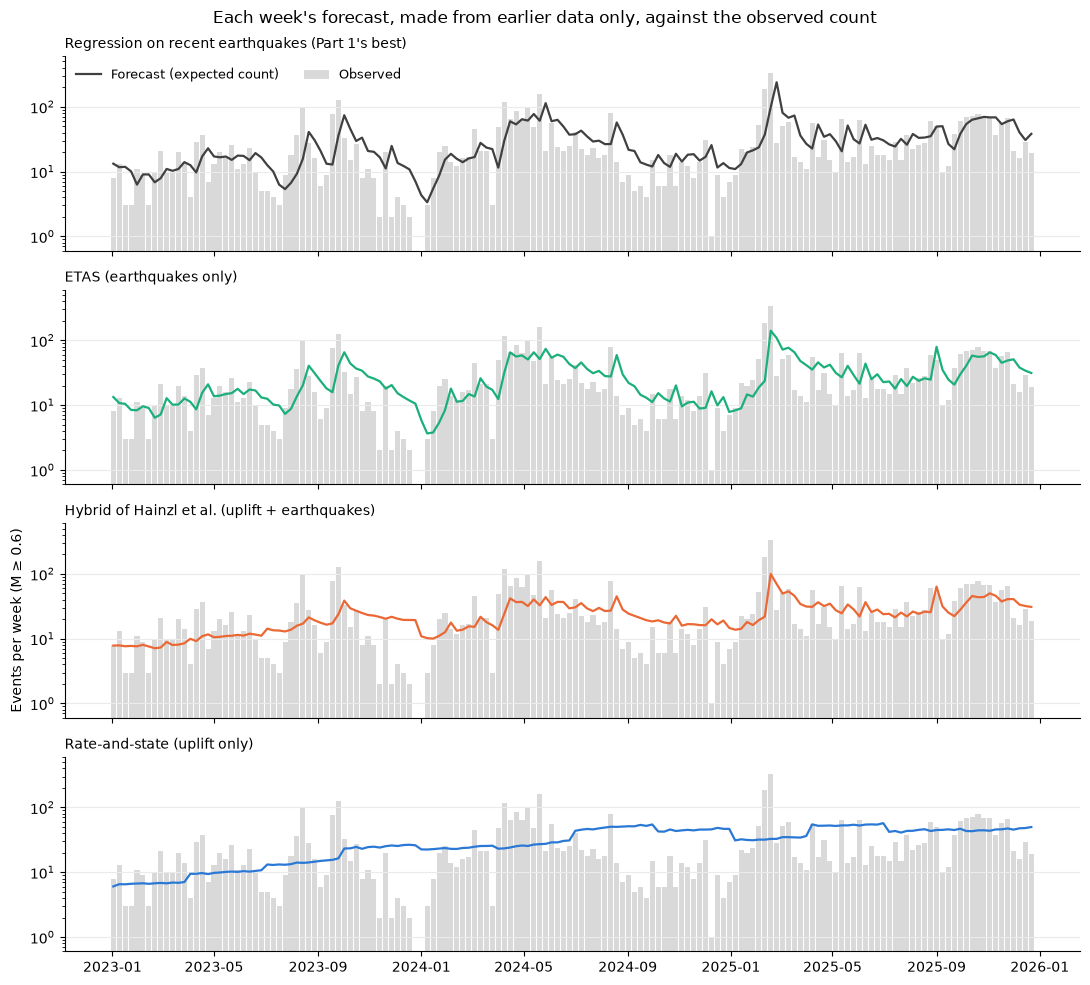

In [19]:
shown_period = slice("2023-01-02", TEST_END)
observed = test["count"].loc[shown_period]
panels = [("glm_seismic", "Regression on recent earthquakes (Part 1's best)", "0.25"),
          ("physics_etas", "ETAS (earthquakes only)", "#1baf7a"),
          ("physics_rs_etas", "Hybrid of Hainzl et al. (uplift + earthquakes)", "#eb6834"),
          ("physics_rs", "Rate-and-state (uplift only)", "#2a78d6")]
fig, axes = plt.subplots(len(panels), 1, figsize=(11, 10), sharex=True, sharey=True)
for ax, (name, title, colour) in zip(axes, panels):
    ax.bar(observed.index, np.maximum(observed, 0.6), width=6, color="0.85", label="Observed")
    ax.plot(counts[name].loc[shown_period], color=colour, linewidth=1.6, label="Forecast (expected count)")
    ax.set_yscale("log")
    ax.set_ylim(0.6, 600)
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(True, axis="y", color="0.92", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
fig.suptitle("Each week's forecast, made from earlier data only, against the observed count")
axes[len(panels) // 2].set_ylabel("Events per week (M ≥ 0.6)")
plt.tight_layout()
fig.savefig("../reports/figures/weekly_forecasts.png", dpi=150, bbox_inches="tight")
plt.show()

**What section 2 shows:**

- **No look-ahead:** every physics forecast is identical with all the data and with only the data before the week; the deliberately leaky forecaster is caught in all three weeks.
- **The week's own aftershocks matter a lot.** In the busy and ordinary 2024 weeks, the simulated mean is 2.3–2.9 times the forecast without them; over all test weeks the median ratio is 2.8 for ETAS and 2.1 for the hybrid. Without them, both models would forecast about 5–6 events a week over 2020–2025 against 16.6 observed; with them, 15.3 (ETAS) and 14.5 (hybrid). With branching ratios close to 1 and most aftershocks within days, a week's count is mostly cascades within that week.
- **The fits need data.** Until 2021 (150–490 events at M ≥ 0.6 since 2005) the hybrid's memory term is switched off (t_a at its upper bound) and its triggering is weak. From 2022 it settles, and the 2025 fit is close to Hainzl et al.'s Table 1 although it uses a different threshold and catalogue: r = 6.1 events/yr, Aσ′ = 0.199 m, t_a = 35 yr, K = 0.042, α = 0.25, p = 1.09. ETAS's branching ratio climbs from 0.58 (2017) to 0.97 (2025): as the unrest grows, ETAS needs ever more triggering to keep up. RS alone jumps between two solutions (t_a of decades or effectively infinite) from one quarter to the next, which shows as steps in its forecast.
- **Weekly counts, Q1 (ML against physics):** the Part 1 GLM on recent seismicity has the best NB log score in both periods. It beats ETAS significantly over 2020–2025 (by 1.7% of the score, interval 0.5–3.0%), not in 2024–2025 (1.2%). It is better than the hybrid by 0.9% (2020–2025) and 1.6% (2024–2025), but neither difference is significant (the 2024–2025 interval only just includes zero). LightGBM is level with the hybrid. So the ML model is at least as good as the physics models, and never worse; the margins are around the 1% that notebook 05 found these tests can detect.
- **Weekly counts, Q2 (does uplift help the physics model?):** the hybrid against ETAS: 0.8% better over 2020–2025, 0.4% worse in 2024–2025; both intervals include zero. **Out of sample, a week ahead, the uplift-driven background adds no detectable skill to ETAS**, although in sample (section 1) it improved the fit by 155 AIC units. In sample, the hybrid wins by explaining the long-term growth; a week ahead, recent seismicity already carries that information, which is the Part 1 finding again, now inside a physics model. The hybrid also forecasts too low in 2024–2025 (28.4 a week against 35.0 observed; ETAS 33.0): its background follows the smooth uplift, and when activity is high its slower triggering (higher p) catches up less.
- **Other comparisons:** ETAS and the hybrid both beat the 4-week rolling mean (ETAS significantly in 2024–2025, by 1.7%). ETAS has the lowest Poisson deviance of all (12.6 against the GLM's 13.4): the deviance is dominated by swarm weeks, after which ETAS reacts most strongly; notebook 05 showed the deviance is a blunt test, so this isn't tested here. RS alone, with no triggering, is worse than the rolling mean (significantly in 2024–2025, by 3.9%): uplift alone is a poor weekly forecast. With the fitted dispersion, every model's NB intervals have about the right coverage (80%: 85–90%; 95%: 95–97%).
- **P(M ≥ 3):** converting the physics forecasts doesn't beat Part 1. The best remains the NB conversion of the 4-week mean (Brier 0.102 / 0.203); the hybrid's is 0.105 / 0.208, ETAS's 0.105 / 0.211. The 4-week mean's conversion beats the hybrid's significantly on log-loss over 2020–2025 (4.6%); the other differences are within noise. In the steady 2024–2025 period the hybrid's forecasts don't rank the risky weeks better than chance (ROC AUC 0.51; the 4-week mean 0.62). Q2 again: hybrid against ETAS, no significant difference on either score.
- **The figure:** ETAS reacts to swarms much like the GLM. The hybrid is smoother and lower in the busy weeks of 2024, and falls back more slowly after swarms, because its background stays where the uplift puts it. RS alone follows only the slow trend.

**Answers so far:** (1) The ML model (GLM on recent seismicity) is at least as good as ETAS and the hybrid, significantly better than ETAS over 2020–2025, and never significantly worse. (2) Making ETAS's background depend on the uplift doesn't measurably improve week-ahead forecasts. (3) Whether the physics forecast helps as an ML input is milestone 5.